In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, shapiro, probplot
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')

# Настройка стиля графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False


In [ ]:
# Акция 1: Загружаем из CSV (SNGS)
df1 = pd.read_csv('date/TQBR_SNGS_2023-01-01_2025-10-01.csv', parse_dates=['date'])
df1.set_index('date', inplace=True)

# Акция 2: Загружаем AT&T через yfinance
mrvl_dat = yf.Ticker("T")
hist_dat = mrvl_dat.history(period="2y")
df2 = hist_dat[['Close']].copy()
df2.columns = ['close']
# Обрезаем до 400 последних наблюдений
df1 = df1.tail(400)
df2 = df2.tail(400)

# Рассчитываем дневные доходности (simple returns)
ret1 = df1['close'].pct_change().dropna()
ret2 = df2['close'].pct_change().dropna()


In [ ]:
print("="*60)
print("ПРОВЕРКА НА НОРМАЛЬНОСТЬ (тест Шапиро-Уилка)")
print("="*60)
print("p-value > 0.05 ⇒ распределение считается нормальным\n")

stat1, p1 = shapiro(ret1)
stat2, p2 = shapiro(ret2)

print(f"Акция 1 (SNGS):")
print(f"statistic = {stat1:.4f}, p-value = {p1:.4f}")
print(f"{'НОРМАЛЬНОЕ' if p1 > 0.05 else ' НЕ нормальное'} распределение\n")

print(f"Акция 2 (AT&T):")
print(f"statistic = {stat2:.4f}, p-value = {p2:.4f}")
print(f"{' НОРМАЛЬНОЕ' if p2 > 0.05 else 'НЕ нормальное'} распределение")

ПРОВЕРКА НА НОРМАЛЬНОСТЬ (тест Шапиро-Уилка)
p-value > 0.05 ⇒ распределение считается нормальным

Акция 1 (SNGS):
statistic = 0.9936, p-value = 0.0878
НОРМАЛЬНОЕ распределение

Акция 2 (AT&T):
statistic = 0.9361, p-value = 0.0000
НЕ нормальное распределение


In [ ]:
def calculate_var_es(returns, confidence_level=0.95):
    """
    Рассчитывает VaR и ES:
    a) историческим методом
    б) параметрическим методом (нормальное распределение)
    """
    alpha = 1 - confidence_level

    # a) Исторический метод
    var_hist = np.percentile(returns, alpha * 100)
    es_hist = returns[returns <= var_hist].mean()

    # б) Параметрический метод (предполагаем нормальное распределение)
    mu = returns.mean()
    sigma = returns.std()
    z = norm.ppf(alpha)  # для 95% это -1.645
    var_param = mu + z * sigma
    es_param = mu - sigma * (norm.pdf(z) / alpha)

    return var_hist, es_hist, var_param, es_param

confidence = 0.95

var1_hist, es1_hist, var1_param, es1_param = calculate_var_es(ret1, confidence)
var2_hist, es2_hist, var2_param, es2_param = calculate_var_es(ret2, confidence)

print("="*60)
print(f"ЗАДАНИЕ 2: VaR и ES (уровень доверия {confidence*100}%)")
print("="*60)

print(f"\n Акция 1 (SNGS):")
print(f"  Исторический метод:   VaR = {var1_hist:.4f} ({var1_hist*100:.2f}%), ES = {es1_hist:.4f} ({es1_hist*100:.2f}%)")
print(f"  Параметрический метод: VaR = {var1_param:.4f} ({var1_param*100:.2f}%), ES = {es1_param:.4f} ({es1_param*100:.2f}%)")

print(f"\n Акция 2 (AT&T):")
print(f"  Исторический метод:   VaR = {var2_hist:.4f} ({var2_hist*100:.2f}%), ES = {es2_hist:.4f} ({es2_hist*100:.2f}%)")
print(f"  Параметрический метод: VaR = {var2_param:.4f} ({var2_param*100:.2f}%), ES = {es2_param:.4f} ({es2_param*100:.2f}%)")

ЗАДАНИЕ 2: VaR и ES (уровень доверия 95.0%)

 Акция 1 (SNGS):
  Исторический метод:   VaR = -0.0320 (-3.20%), ES = -0.0411 (-4.11%)
  Параметрический метод: VaR = -0.0340 (-3.40%), ES = -0.0425 (-4.25%)

 Акция 2 (AT&T):
  Исторический метод:   VaR = -0.0260 (-2.60%), ES = -0.0434 (-4.34%)
  Параметрический метод: VaR = -0.0279 (-2.79%), ES = -0.0348 (-3.48%)


In [ ]:
def bootstrap_var(returns, n_bootstraps=1000, confidence_level=0.95):
    """
    Применяет бутстреп для оценки VaR:
    a) стандартное отклонение VaR
    б) доверительные интервалы (непараметрический и параметрический)
    """
    alpha = 1 - confidence_level
    boot_vars = []

    for _ in range(n_bootstraps):
        sample = np.random.choice(returns, size=len(returns), replace=True)
        boot_vars.append(np.percentile(sample, alpha * 100))

    boot_vars = np.array(boot_vars)

    # а) Стандартное отклонение VaR
    std_var = boot_vars.std()

    # б) Доверительные интервалы
    # Непараметрический (через перцентили бутстреп-распределения)
    ci_nonparam_lower = np.percentile(boot_vars, 2.5)
    ci_nonparam_upper = np.percentile(boot_vars, 97.5)

    # Параметрический (через среднее и стандартное отклонение)
    mean_var = boot_vars.mean()
    ci_param_lower = mean_var - 1.96 * std_var
    ci_param_upper = mean_var + 1.96 * std_var

    return std_var, ci_nonparam_lower, ci_nonparam_upper, ci_param_lower, ci_param_upper, boot_vars

print(" Функция bootstrap_var() определена")
print("   - 1000 бутстреп-выборок")
print("   - Стандартное отклонение VaR")
print("   - ДИ непараметрический (2.5%, 97.5%)")
print("   - ДИ параметрический (mean ± 1.96·std)")
std1, ci1_np_l, ci1_np_u, ci1_p_l, ci1_p_u, boot_vars1 = bootstrap_var(ret1)
std2, ci2_np_l, ci2_np_u, ci2_p_l, ci2_p_u, boot_vars2 = bootstrap_var(ret2)

print("="*60)
print("ЗАДАНИЕ 3: БУТСТРЕП")
print("="*60)

print(f"\n📈 Акция 1 (SNGS):")
print(f"  Стандартное отклонение VaR: {std1:.5f} ({std1*100:.3f}%)")
print(f"  ДИ (непараметрический): [{ci1_np_l:.4f}, {ci1_np_u:.4f}]")
print(f"  ДИ (параметрический):   [{ci1_p_l:.4f}, {ci1_p_u:.4f}]")

print(f"\n📈 Акция 2 (AT&T):")
print(f"  Стандартное отклонение VaR: {std2:.5f} ({std2*100:.3f}%)")
print(f"  ДИ (непараметрический): [{ci2_np_l:.4f}, {ci2_np_u:.4f}]")
print(f"  ДИ (параметрический):   [{ci2_p_l:.4f}, {ci2_p_u:.4f}]")

✅ Функция bootstrap_var() определена
   - 1000 бутстреп-выборок
   - Стандартное отклонение VaR
   - ДИ непараметрический (2.5%, 97.5%)
   - ДИ параметрический (mean ± 1.96·std)
ЗАДАНИЕ 3: БУТСТРЕП

📈 Акция 1 (SNGS):
  Стандартное отклонение VaR: 0.00213 (0.213%)
  ДИ (непараметрический): [-0.0378, -0.0288]
  ДИ (параметрический):   [-0.0362, -0.0279]

📈 Акция 2 (AT&T):
  Стандартное отклонение VaR: 0.00278 (0.278%)
  ДИ (непараметрический): [-0.0312, -0.0218]
  ДИ (параметрический):   [-0.0317, -0.0208]


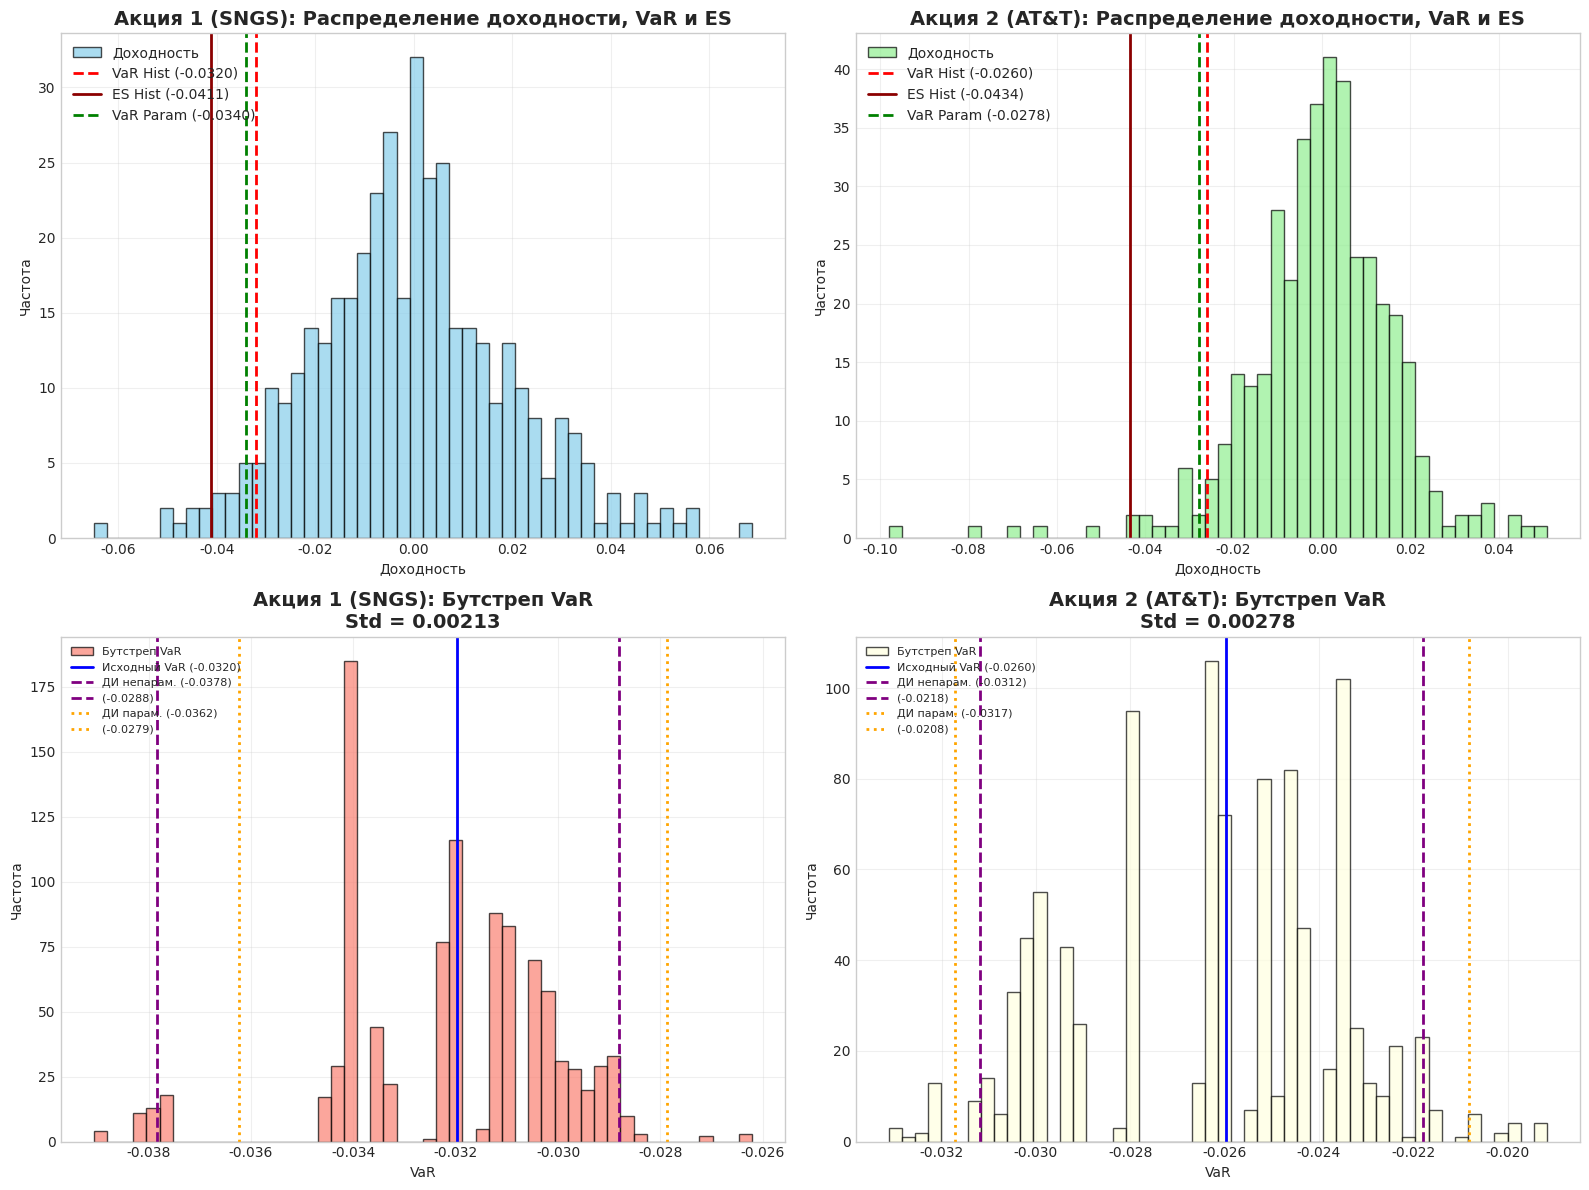

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Гистограмма доходностей Акция 1 (SNGS)
axes[0, 0].hist(ret1, bins=50, color='skyblue', edgecolor='black', alpha=0.7, label='Доходность')
axes[0, 0].axvline(var1_hist, color='red', linestyle='--', linewidth=2, label=f'VaR Hist ({var1_hist:.4f})')
axes[0, 0].axvline(es1_hist, color='darkred', linestyle='-', linewidth=2, label=f'ES Hist ({es1_hist:.4f})')
axes[0, 0].axvline(var1_param, color='green', linestyle='--', linewidth=2, label=f'VaR Param ({var1_param:.4f})')
axes[0, 0].set_title('Акция 1 (SNGS): Распределение доходности, VaR и ES', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Доходность')
axes[0, 0].set_ylabel('Частота')
axes[0, 0].legend(loc='upper left')
axes[0, 0].grid(True, alpha=0.3)

# Гистограмма доходностей Акция 2 (AT&T)
axes[0, 1].hist(ret2, bins=50, color='lightgreen', edgecolor='black', alpha=0.7, label='Доходность')
axes[0, 1].axvline(var2_hist, color='red', linestyle='--', linewidth=2, label=f'VaR Hist ({var2_hist:.4f})')
axes[0, 1].axvline(es2_hist, color='darkred', linestyle='-', linewidth=2, label=f'ES Hist ({es2_hist:.4f})')
axes[0, 1].axvline(var2_param, color='green', linestyle='--', linewidth=2, label=f'VaR Param ({var2_param:.4f})')
axes[0, 1].set_title('Акция 2 (AT&T): Распределение доходности, VaR и ES', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Доходность')
axes[0, 1].set_ylabel('Частота')
axes[0, 1].legend(loc='upper left')
axes[0, 1].grid(True, alpha=0.3)

# Гистограмма Бутстреп VaR Акция 1 (SNGS)
axes[1, 0].hist(boot_vars1, bins=50, color='salmon', edgecolor='black', alpha=0.7, label='Бутстреп VaR')
axes[1, 0].axvline(var1_hist, color='blue', linestyle='-', linewidth=2, label=f'Исходный VaR ({var1_hist:.4f})')
axes[1, 0].axvline(ci1_np_l, color='purple', linestyle='--', linewidth=2, label=f'ДИ непарам. ({ci1_np_l:.4f})')
axes[1, 0].axvline(ci1_np_u, color='purple', linestyle='--', linewidth=2, label=f'({ci1_np_u:.4f})')
axes[1, 0].axvline(ci1_p_l, color='orange', linestyle=':', linewidth=2, label=f'ДИ парам. ({ci1_p_l:.4f})')
axes[1, 0].axvline(ci1_p_u, color='orange', linestyle=':', linewidth=2, label=f'({ci1_p_u:.4f})')
axes[1, 0].set_title(f'Акция 1 (SNGS): Бутстреп VaR\nStd = {std1:.5f}', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('VaR')
axes[1, 0].set_ylabel('Частота')
axes[1, 0].legend(loc='upper left', fontsize=8)
axes[1, 0].grid(True, alpha=0.3)

# Гистограмма Бутстреп VaR Акция 2 (AT&T)
axes[1, 1].hist(boot_vars2, bins=50, color='lightyellow', edgecolor='black', alpha=0.7, label='Бутстреп VaR')
axes[1, 1].axvline(var2_hist, color='blue', linestyle='-', linewidth=2, label=f'Исходный VaR ({var2_hist:.4f})')
axes[1, 1].axvline(ci2_np_l, color='purple', linestyle='--', linewidth=2, label=f'ДИ непарам. ({ci2_np_l:.4f})')
axes[1, 1].axvline(ci2_np_u, color='purple', linestyle='--', linewidth=2, label=f'({ci2_np_u:.4f})')
axes[1, 1].axvline(ci2_p_l, color='orange', linestyle=':', linewidth=2, label=f'ДИ парам. ({ci2_p_l:.4f})')
axes[1, 1].axvline(ci2_p_u, color='orange', linestyle=':', linewidth=2, label=f'({ci2_p_u:.4f})')
axes[1, 1].set_title(f'Акция 2 (AT&T): Бутстреп VaR\nStd = {std2:.5f}', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('VaR')
axes[1, 1].set_ylabel('Частота')
axes[1, 1].legend(loc='upper left', fontsize=8)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()